# Validação Single-Subject Fisiologia (SPA-fNIRS) | Tarefa: Stroop
Este script valida a extração dos dados periféricos WINGS (GSR e Frequência Cardíaca) para um único sujeito (`sub-001`) na tarefa de controlo inibitório (Stroop).
A validação é composta por:
1. Extração do `.zip` e leitura do sinal bruto.
2. Sincronização temporal dos marcadores 'Congruente' (1) e 'Incongruente' (2) a partir do ficheiro `.snirf`.
3. Filtragem passa-baixo (GSR) e segmentação em épocas (-2 a 15 segundos).
4. Extração das métricas fásicas (Amplitude de Stress e Bradicardia).

A carregar o ficheiro WINGS do Stroop para sub-001...

Dados carregados com sucesso! Linhas totais: 196589


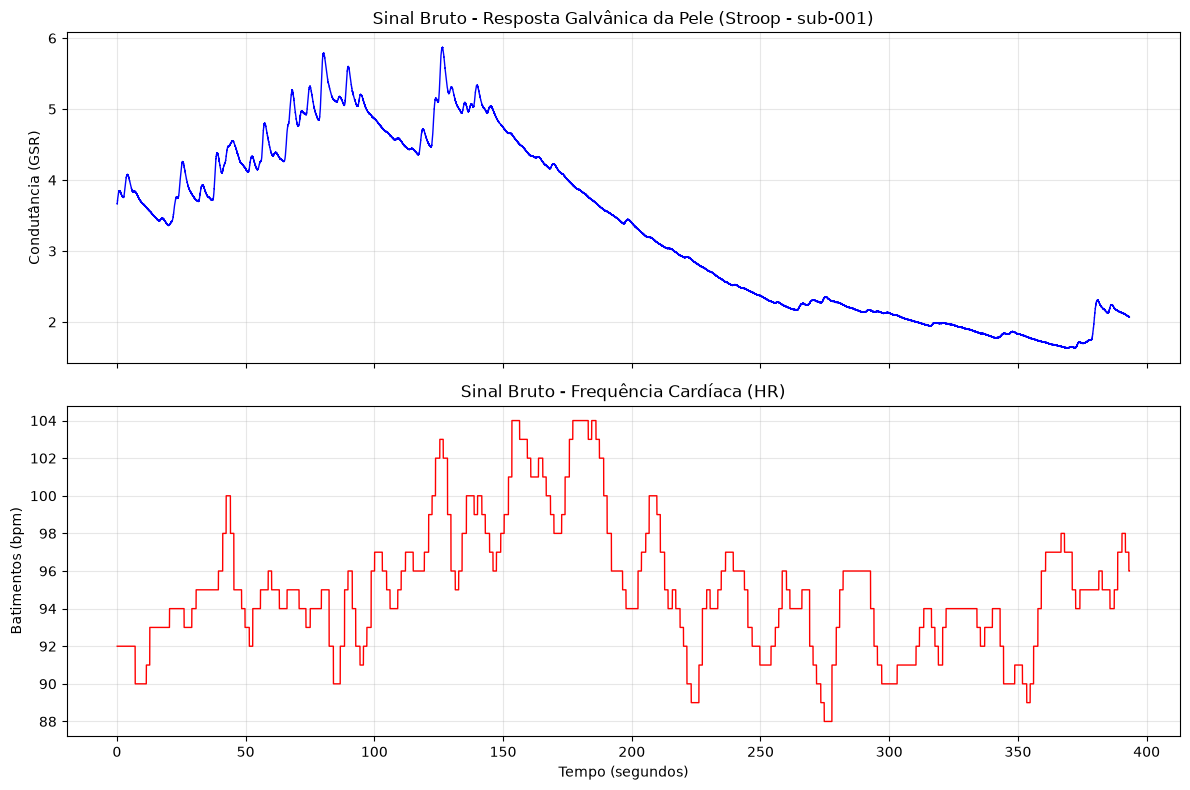

In [4]:
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. Configuração e Caminhos (Raw Data)
# ==========================================
BASE_DIR = r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
SUJEITO = "sub-001"
TAREFA = "tk-stroop"

print(f"A carregar o ficheiro WINGS do Stroop para {SUJEITO}...")

pasta_nirs = os.path.join(BASE_DIR, SUJEITO, "nirs")
nome_pasta_run = next((p for p in os.listdir(pasta_nirs) if TAREFA in p.lower()), None)
pasta_alvo = os.path.join(pasta_nirs, nome_pasta_run)
pasta_extraida_wings = os.path.join(pasta_alvo, "dados_wings_extraidos")

# Descompactar automaticamente se necessário
if not os.path.exists(pasta_extraida_wings):
    print("A descompactar ficheiro .zip do WINGS...")
    zip_file = next((f for f in os.listdir(pasta_alvo) if f.endswith('.zip')), None)
    with zipfile.ZipFile(os.path.join(pasta_alvo, zip_file), 'r') as zip_ref:
        zip_ref.extractall(pasta_extraida_wings)

# Ler WINGS
wings_file = next((f for f in os.listdir(pasta_extraida_wings) if f.endswith('.wings')), None)
caminho_wings = os.path.join(pasta_extraida_wings, wings_file)

df_wings = pd.read_csv(caminho_wings, sep=';', skiprows=1)
df_wings.columns = df_wings.columns.str.strip()

print(f"\nDados carregados com sucesso! Linhas totais: {len(df_wings)}")

# ==========================================
# 2. Inspeção Visual do Sinal Bruto
# ==========================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# GSR Bruto
ax1.plot(df_wings['SecondsSinceRunStart'], df_wings['GSR'], color='blue', linewidth=1)
ax1.set_ylabel('Condutância (GSR)')
ax1.set_title(f'Sinal Bruto - Resposta Galvânica da Pele (Stroop - {SUJEITO})')
ax1.grid(True, alpha=0.3)

# HR Bruto
ax2.plot(df_wings['SecondsSinceRunStart'], df_wings['HR'], color='red', linewidth=1)
ax2.set_xlabel('Tempo (segundos)')
ax2.set_ylabel('Batimentos (bpm)')
ax2.set_title('Sinal Bruto - Frequência Cardíaca (HR)')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 3. Sincronização LSL e Epoching (-2s a 15s)
Leitura do `.snirf` para resgatar os instantes exatos de início dos blocos *Congruente* ('1') e *Incongruente* ('2'). O sinal GSR é sujeito a um filtro Butterworth passa-baixo (5 Hz) para remover ruído elétrico, e os blocos são segmentados subtraindo a linha de base (-2 a 0 segundos).

Blocos detetados via LSL: 5 Congruentes | 5 Incongruentes


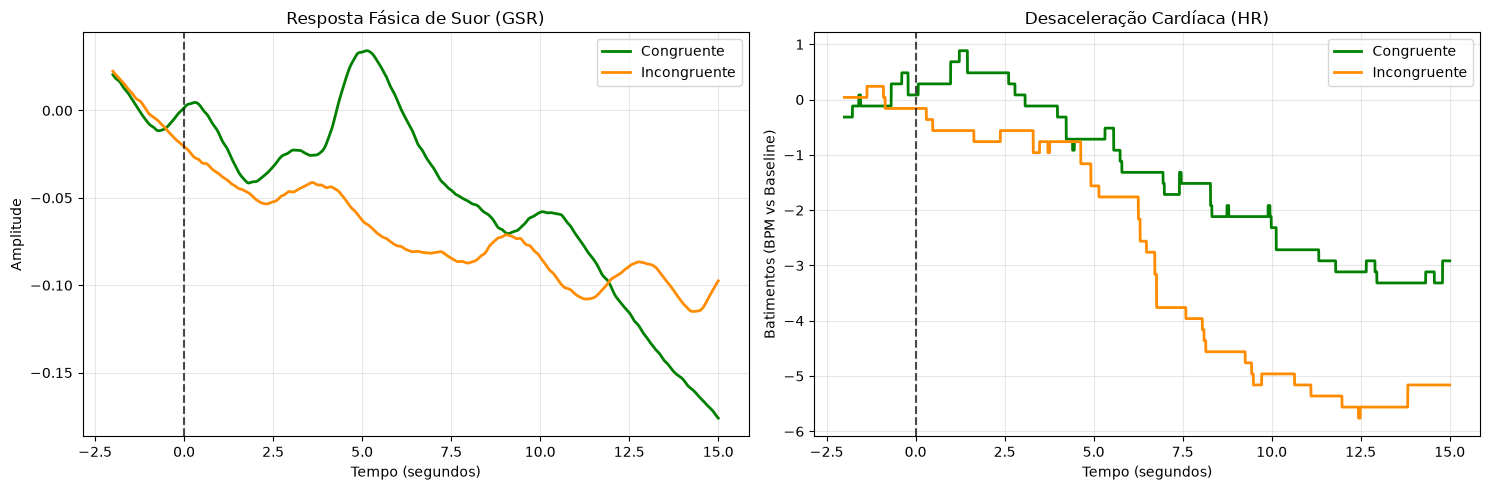


--- MÉTRICAS EXTRAÍDAS (Para o Batch) ---
GSR Incongruente Max (Stress): 0.0225
GSR Congruente Max (Stress):   0.0342
HR Incongruente Min (Foco):    -5.7608
HR Congruente Min (Foco):      -3.3161


In [5]:
import mne
from scipy.signal import butter, filtfilt
warnings.filterwarnings('ignore')
mne.set_log_level('WARNING')

# 3.1 Ler Triggers do fNIRS
snirf_file = next((f for f in os.listdir(pasta_alvo) if f.endswith('.snirf')), None)
raw_temp = mne.io.read_raw_snirf(os.path.join(pasta_alvo, snirf_file), preload=False, verbose=False)

tempos_congruente = [onset for onset, desc in zip(raw_temp.annotations.onset, raw_temp.annotations.description) if desc == '1']
tempos_incongruente = [onset for onset, desc in zip(raw_temp.annotations.onset, raw_temp.annotations.description) if desc == '2']

print(f"Blocos detetados via LSL: {len(tempos_congruente)} Congruentes | {len(tempos_incongruente)} Incongruentes")

# 3.2 Sincronizar e Segmentar (GSR e HR)
tempos_wings = df_wings['SecondsSinceRunStart'].values
fs_wings = len(tempos_wings) / tempos_wings[-1]

indices_con = [np.argmin(np.abs(tempos_wings - t)) for t in tempos_congruente]
indices_inc = [np.argmin(np.abs(tempos_wings - t)) for t in tempos_incongruente]

amostras_antes = int(2.0 * fs_wings)  # 2 segundos de baseline
amostras_depois = int(15.0 * fs_wings) # 15 segundos de bloco

# Filtrar GSR
nyq = 0.5 * fs_wings
b, a = butter(4, 5.0 / nyq, btype='low', analog=False)
gsr_filtrado = filtfilt(b, a, df_wings['GSR'].values)
hr_bruto = df_wings['HR'].values

def segmentar(sinal, indices):
    epocas = []
    for idx in indices:
        if idx - amostras_antes >= 0 and idx + amostras_depois < len(sinal):
            chunk = sinal[idx - amostras_antes : idx + amostras_depois]
            epocas.append(chunk - np.mean(chunk[0:amostras_antes])) # Subtrai baseline
    return np.mean(np.array(epocas), axis=0) if epocas else np.array([])

# Médias Fásicas
gsr_medio_con = segmentar(gsr_filtrado, indices_con)
gsr_medio_inc = segmentar(gsr_filtrado, indices_inc)

hr_medio_con = segmentar(hr_bruto, indices_con)
hr_medio_inc = segmentar(hr_bruto, indices_inc)

# ==========================================
# 3.3 Visualização das Curvas Médias (ERPs)
# ==========================================
vetor_tempo = np.linspace(-2.0, 15.0, len(gsr_medio_inc))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot GSR
ax1.plot(vetor_tempo, gsr_medio_con, color='green', linewidth=2, label='Congruente')
ax1.plot(vetor_tempo, gsr_medio_inc, color='darkorange', linewidth=2, label='Incongruente')
ax1.axvline(x=0, color='black', linestyle='--', alpha=0.7)
ax1.set_title("Resposta Fásica de Suor (GSR)")
ax1.set_xlabel("Tempo (segundos)")
ax1.set_ylabel("Amplitude")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot HR
ax2.plot(vetor_tempo, hr_medio_con, color='green', linewidth=2, label='Congruente')
ax2.plot(vetor_tempo, hr_medio_inc, color='darkorange', linewidth=2, label='Incongruente')
ax2.axvline(x=0, color='black', linestyle='--', alpha=0.7)
ax2.set_title("Desaceleração Cardíaca (HR)")
ax2.set_xlabel("Tempo (segundos)")
ax2.set_ylabel("Batimentos (BPM vs Baseline)")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# 3.4 Extração de Métricas Finais
# ==========================================
print("\n--- MÉTRICAS EXTRAÍDAS (Para o Batch) ---")
print(f"GSR Incongruente Max (Stress): {np.max(gsr_medio_inc):.4f}")
print(f"GSR Congruente Max (Stress):   {np.max(gsr_medio_con):.4f}")
print(f"HR Incongruente Min (Foco):    {np.min(hr_medio_inc):.4f}")
print(f"HR Congruente Min (Foco):      {np.min(hr_medio_con):.4f}")